# SwiftCart Online Retail Analytics using Python
## Sprint 2 – Exploratory Data Analysis & Visualization

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("SwiftCart_Cleaned_Dataset.csv", parse_dates=["Date"])
df.head()

,Order ID,Cust ID,Gender,Age,Age Group,Date,Month,Status,Channel,SKU,Category,Size,Qty,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,B2B
0,171-1029312-3038738,"1,029,312.00",Women,NaN,Adult,2022-12-04,Dec,Delivered,Myntra,JNE1233-BLUE-KR-031-XXL,kurta,XXL,1,INR,376,MOHALI,PUNJAB,140301,IN,False
1,405-2183842-2225946,"2,183,842.00",Women,29.00,Teenager,2022-12-04,Dec,Delivered,Ajio,SET414-KR-NP-L,Set,L,1,INR,1449,GURUGRAM,HARYANA,122002,IN,False
2,171-1641533-8921966,"1,641,533.00",Women,67.00,Senior,2022-12-04,Dec,Delivered,Myntra,SET261-KR-PP-S,Set,S,1,INR,453,KOLKATA,WEST BENGAL,700029,IN,False
3,404-7490807-6300351,"7,490,807.00",Women,20.00,Teenager,2022-12-04,Dec,Delivered,Amazon,SET110-KR-PP-M,Set,M,1,INR,729,THANJAVUR,TAMIL NADU,613007,IN,False
4,403-9293516-4577154,"9,293,516.00",Women,62.00,Senior,2022-12-04,Dec,Delivered,Myntra,JNE2294-KR-A-XXL,kurta,XXL,1,INR,544,GURUGRAM,HARYANA,122001,IN,False


## 1. Descriptive Analysis

### Question: What are the central tendency and dispersion of sales amount?

In [3]:
df["Amount"].describe(percentiles=[.25,.50,.75,.90,.95,.99])

count   31,047.00
mean       682.07
std        268.58
min        229.00
25%        486.00
50%        646.00
75%        794.00
90%      1,099.00
95%      1,186.00
99%      1,442.00
max      3,036.00
Name: Amount, dtype: float64

**Observation:** The average line-item sales amount is about ₹682, while the median is lower, indicating a right-skewed distribution with some higher-value observations.

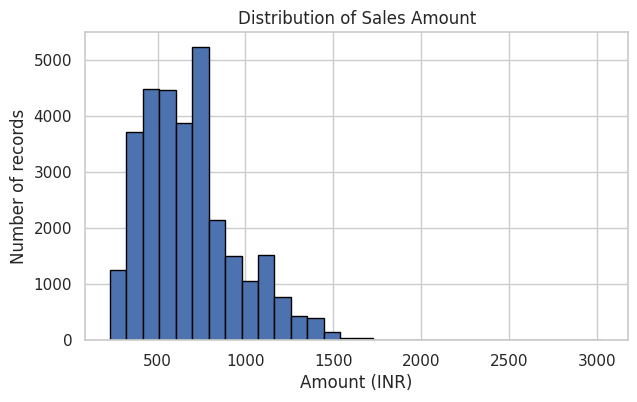

In [4]:
fig, ax = plt.subplots(figsize=(7,4))
ax.hist(df["Amount"], bins=30, edgecolor="black")
ax.set_title("Distribution of Sales Amount")
ax.set_xlabel("Amount (INR)")
ax.set_ylabel("Number of records")
plt.show()

**Observation → Interpretation → Business Insight:** Most line-item amounts cluster in the lower-to-middle range, with a right tail. SwiftCart should avoid relying only on the mean when describing typical transaction value.

## 2. Customer Analysis

### Question: What is the customer distribution by gender and age group?

In [5]:
pd.crosstab(df["Gender"], df["Age Group"], margins=True)

Age Group,Adult,Senior,Teenager,All
Gender,,,,
Men,4470,1713,2649,8832
Women,10007,3988,6108,20103
All,14477,5701,8757,28935


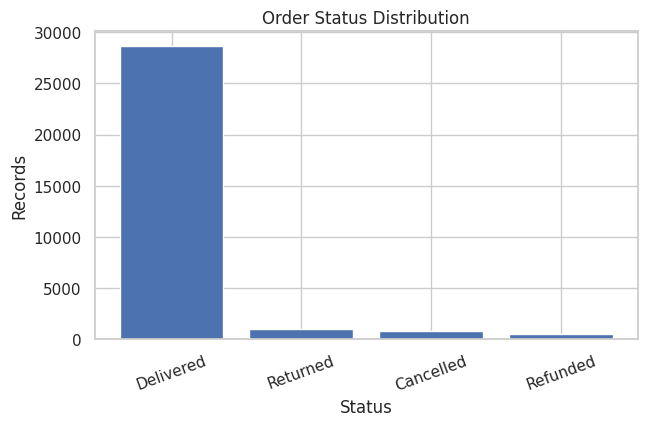

In [6]:
fig, ax = plt.subplots(figsize=(7,4))
status_counts = df["Status"].value_counts()
ax.bar(status_counts.index, status_counts.values)
ax.set_title("Order Status Distribution")
ax.set_xlabel("Status")
ax.set_ylabel("Records")
plt.xticks(rotation=20)
plt.show()

**Observation:** Women account for more records than men, and the Adult group is the largest age group. This suggests that customer engagement and product strategy should pay particular attention to these segments, while still monitoring smaller segments.

## 3. Product Analysis

### Question: Which product categories have the highest sales and demand?

In [7]:
category_summary = df.groupby("Category").agg(
    Sales=("Amount","sum"),
    Quantity=("Qty","sum"),
    Records=("SKU","size")
).sort_values("Sales", ascending=False)
category_summary

,Sales,Quantity,Records
Category,,,
Set,10507546,12522,12391
kurta,4959377,10630,10446
Western Dress,3148836,4084,4066
Top,1186199,2217,2193
Saree,1010471,1389,1380
Ethnic Dress,195256,264,264
Blouse,140888,234,229
Bottom,27804,78,78


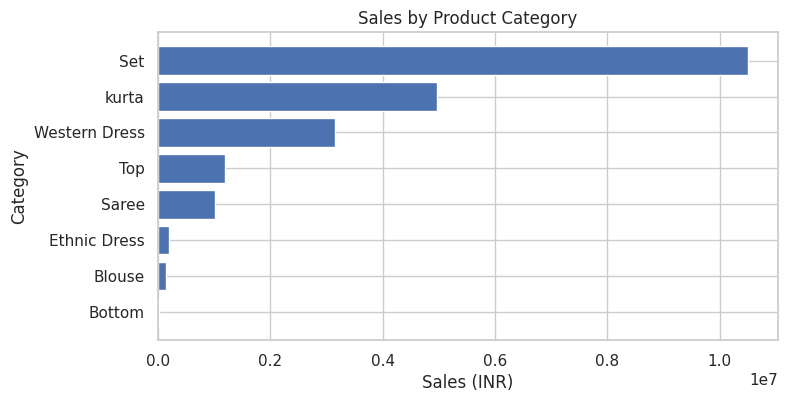

In [8]:
fig, ax = plt.subplots(figsize=(8,4))
plot_df = category_summary.sort_values("Sales")
ax.barh(plot_df.index, plot_df["Sales"])
ax.set_title("Sales by Product Category")
ax.set_xlabel("Sales (INR)")
ax.set_ylabel("Category")
plt.show()

**Observation:** `Set` is the strongest category by both sales and record volume, followed by `kurta` and `Western Dress`. `Bottom` has the lowest sales among the listed categories.

### Question: Which sizes are most frequently ordered?

In [9]:
df["Size"].value_counts().sort_values(ascending=False)

Size
M       5485
L       5144
XL      4437
S       4176
XXL     4065
3XL     3347
XS      2503
Free    1408
6XL      208
5XL      161
4XL      113
Name: count, dtype: int64

**Observation:** M and L are the most common sizes, followed by XL and S. Inventory planning should ensure strong availability in these sizes.

## 4. Sales Analysis

### Question: Which sales channels contribute the most sales?

In [10]:
channel_summary = df.groupby("Channel ").agg(
    Sales=("Amount","sum"),
    Records=("Order ID","size"),
    Average_Amount=("Amount","mean")
).sort_values("Sales", ascending=False)
channel_summary

,Sales,Records,Average_Amount
Channel,,,
Amazon,7519933,11016,682.64
Myntra,4941540,7254,681.22
Flipkart,4573301,6703,682.28
Ajio,1331427,1931,689.50
Nalli,1015329,1484,684.18
Meesho,927606,1398,663.52
Others,867241,1261,687.74


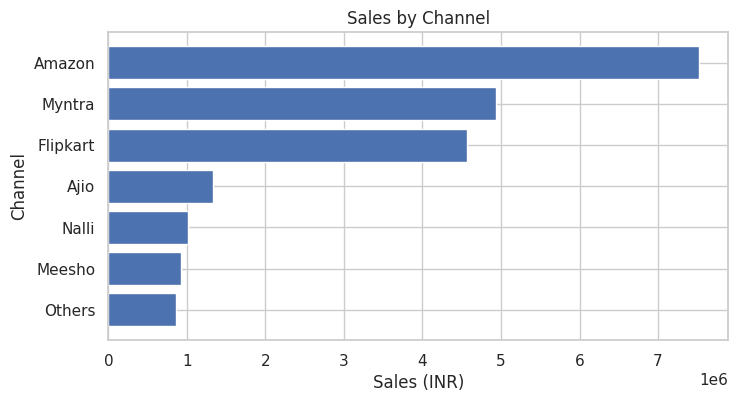

In [11]:
fig, ax = plt.subplots(figsize=(8,4))
plot_df = channel_summary.sort_values("Sales")
ax.barh(plot_df.index, plot_df["Sales"])
ax.set_title("Sales by Channel")
ax.set_xlabel("Sales (INR)")
ax.set_ylabel("Channel")
plt.show()

**Observation:** Amazon contributes the highest sales, followed by Myntra and Flipkart. The average line-item amount is relatively similar across channels, so channel sales differences are primarily associated with volume.

## 5. Order Analysis

### Question: What is the distribution of order status?

In [12]:
status_summary = df.groupby("Status").agg(
    Records=("Order ID","size"),
    Orders=("Order ID","nunique"),
    Sales=("Amount","sum")
).sort_values("Records", ascending=False)
status_summary

,Records,Orders,Sales
Status,,,
Delivered,28641,25513,19710544
Returned,1045,968,719147
Cancelled,844,800,481844
Refunded,517,480,264842


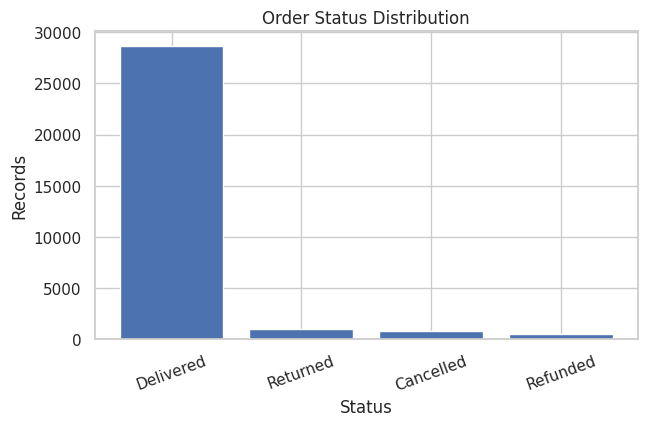

In [13]:
fig, ax = plt.subplots(figsize=(7,4))
status_counts = df["Status"].value_counts()
ax.bar(status_counts.index, status_counts.values)
ax.set_title("Order Status Distribution")
ax.set_xlabel("Status")
ax.set_ylabel("Records")
plt.xticks(rotation=20)
plt.show()

**Observation:** Delivered is overwhelmingly the most common status. Returned, Cancelled, and Refunded represent much smaller portions of the records, but they still represent operational and customer-experience signals.

## 6. Time-Based Analysis

### Question: How does sales activity vary by month?

In [14]:
month_order = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
monthly = df.groupby("Month")["Amount"].agg(["sum","count"]).reindex(month_order)
monthly

,sum,count
Month,,
Jan,1819124,2701
Feb,1875044,2749
Mar,1928066,2819
Apr,1828764,2684
May,1797347,2616
Jun,1750966,2597
Jul,1771565,2578
Aug,1808505,2617
Sep,1688130,2489


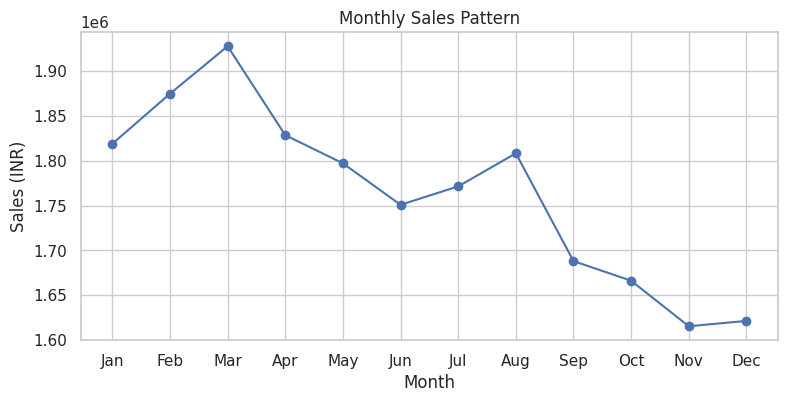

In [15]:
fig, ax = plt.subplots(figsize=(9,4))
ax.plot(monthly.index, monthly["sum"], marker="o")
ax.set_title("Monthly Sales Pattern")
ax.set_xlabel("Month")
ax.set_ylabel("Sales (INR)")
plt.show()

**Observation:** Sales are highest in March and February among the available month labels, while November is the lowest. The pattern is useful for seasonal planning, but the source date field covers one observed year and has some missing values.

## 7. Group-Based Analysis

### Question: Which states generate the highest sales?

In [16]:
state_summary = df.groupby("ship-state").agg(
    Sales=("Amount","sum"),
    Records=("Order ID","size")
).sort_values("Sales", ascending=False)
state_summary.head(10)

,Sales,Records
ship-state,,
MAHARASHTRA,2990221,4519
KARNATAKA,2646358,3988
UTTAR PRADESH,2104659,2882
TELANGANA,1712439,2527
TAMIL NADU,1678877,2679
DELHI,1248111,1804
KERALA,1008940,1549
WEST BENGAL,922444,1425
ANDHRA PRADESH,918499,1369


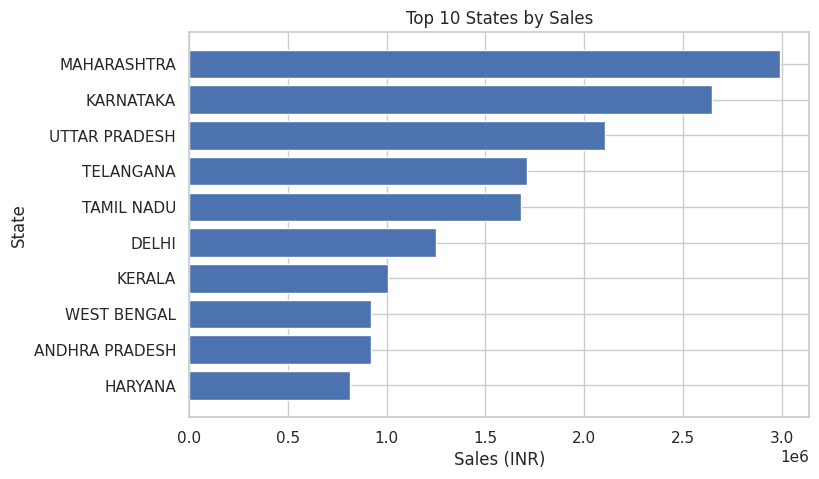

In [17]:
fig, ax = plt.subplots(figsize=(8,5))
plot_df = state_summary.head(10).sort_values("Sales")
ax.barh(plot_df.index, plot_df["Sales"])
ax.set_title("Top 10 States by Sales")
ax.set_xlabel("Sales (INR)")
ax.set_ylabel("State")
plt.show()

**Observation:** Maharashtra has the highest sales, followed by Karnataka and Uttar Pradesh. These states are important markets for regional planning.

## 8. Pivot Table Analysis

### Question: How do category sales vary across channels?

In [18]:
pivot_category_channel = pd.pivot_table(
    df, values="Amount", index="Category", columns="Channel ", aggfunc="sum", fill_value=0
)
pivot_category_channel

Channel,Ajio,Amazon,Flipkart,Meesho,Myntra,Nalli,Others
Category,,,,,,,
Blouse,46952,4334,1865,27776,58277,339,1345
Bottom,3193,6153,5151,660,10229,1425,993
Ethnic Dress,16266,74919,39947,7655,42517,9579,4373
Saree,6960,401371,262378,9606,230276,54688,45192
Set,680195,3752298,2286157,455135,2398712,496425,438624
Top,86142,408675,265862,50674,278565,54145,42136
Western Dress,193972,1122380,663511,127247,752061,159985,129680
kurta,297747,1749803,1048430,248853,1170903,238743,204898


**Observation:** The pivot table provides a business view of which product categories perform across each sales channel, supporting channel-specific assortment decisions.

### Question: How do order statuses vary by channel?

In [19]:
pivot_channel_status = pd.pivot_table(
    df, values="Order ID", index="Channel ", columns="Status", aggfunc="count", fill_value=0
)
pivot_channel_status

Status,Cancelled,Delivered,Refunded,Returned
Channel,,,,
Ajio,51,1737,23,60
Amazon,299,9752,192,371
Flipkart,177,5972,106,215
Meesho,37,1246,25,45
Myntra,185,6487,111,230
Nalli,31,1322,22,52
Others,33,1134,16,36


**Observation:** Status counts can be compared across channels to identify where operational outcomes differ in volume.

## 9. Crosstab Analysis

### Question: How are order statuses distributed across channels?

In [20]:
ct = pd.crosstab(df["Channel "], df["Status"])
ct

Status,Cancelled,Delivered,Refunded,Returned
Channel,,,,
Ajio,54,1793,24,60
Amazon,308,10124,201,383
Flipkart,188,6173,113,229
Meesho,38,1288,25,47
Myntra,188,6713,116,237
Nalli,34,1375,22,53
Others,34,1175,16,36


**Observation:** Delivered records dominate every major channel. Crosstab analysis is useful because it compares two categorical dimensions without assuming a causal relationship.

## 10. Relationship Analysis

### Question: Is quantity associated with sales amount?

In [21]:
df[["Qty","Amount"]].corr()

,Qty,Amount
Qty,1.00,0.05
Amount,0.05,1.00


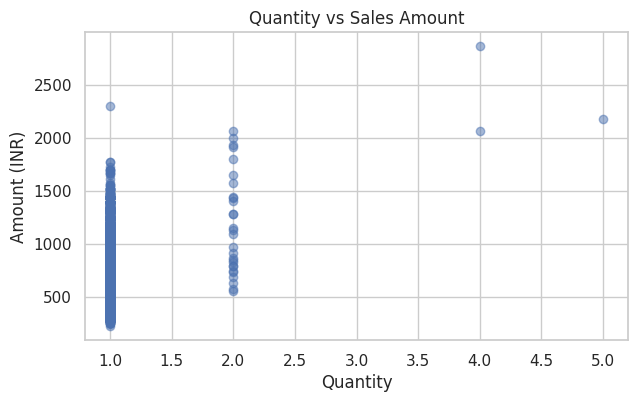

In [22]:
fig, ax = plt.subplots(figsize=(7,4))
sample = df.sample(min(5000, len(df)), random_state=42)
ax.scatter(sample["Qty"], sample["Amount"], alpha=.5)
ax.set_title("Quantity vs Sales Amount")
ax.set_xlabel("Quantity")
ax.set_ylabel("Amount (INR)")
plt.show()

**Observation:** The correlation and scatter plot should be interpreted as association, not causation. Quantity has limited variation, so it is not expected to explain all variation in amount.

## 11. Geographic and Channel Business View

In [23]:
geo_channel = pd.pivot_table(
    df, values="Amount", index="ship-state", columns="Channel ", aggfunc="sum", fill_value=0
)
geo_channel.head(10)

Channel,Ajio,Amazon,Flipkart,Meesho,Myntra,Nalli,Others
ship-state,,,,,,,
ANDAMAN & NICOBAR,5264,16695,15436,2082,7118,4117,1258
ANDHRA PRADESH,58452,307210,198399,39115,230903,41531,42889
ARUNACHAL PRADESH,2956,11962,8925,2814,5278,1884,1184
ASSAM,29299,116965,75304,9826,66594,13502,14933
Arunachal Pradesh,0,646,589,0,0,0,0
Arunachal pradesh,0,301,0,0,301,0,0
BIHAR,31992,142168,111161,12954,107565,19859,14352
Bihar,0,2419,0,664,1441,0,824
CHANDIGARH,1988,26204,11531,5465,12143,2473,922


**Observation:** This combined view supports regional channel strategy by showing where each channel contributes sales.

## 12. Sprint 2 Business Insights

1. **Customers:** Women and Adults represent the largest record volumes.
2. **Products:** Set is the leading category by sales and quantity; M and L are the most common sizes.
3. **Sales:** Amazon has the largest sales contribution among channels.
4. **Orders:** Delivered is the dominant status.
5. **Time:** March has the highest observed monthly sales; November is the lowest.
6. **Geography:** Maharashtra, Karnataka, and Uttar Pradesh are the leading states by sales.

These are descriptive findings from the cleaned dataset and should be statistically validated in Sprint 3.